# 04. Novel Contribution: Explanation Stability Across Regimes
## Noise Floor, Explanation Shift Ratio (ESR), & Covariate Shift Control


Our core research question: *Do SHAP-based explanations of road-accident risk remain stable across weather and traffic conditions, or does the model rely on different factors in different regimes?*


In [1]:
import os, sys
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")

import pandas as pd
from IPython.display import Image, display

# Stability Summary Table
stab_df = pd.read_csv("results/tables/stability_summary.csv")
stab_df


,regime_a,regime_b,model,protocol,metric,value,ci_low,ci_high,noise_floor,ESR,p_value,effect_size,survives_shift_control,p_holm
0,rain,clear,XGBoost,P1 (Global Model Sliced),cosine_distance,0.0001,0.0000,0.0001,0.0,2.429,0.858,-0.819,True,1.000
1,high_wind,clear,XGBoost,P1 (Global Model Sliced),cosine_distance,0.0000,0.0000,0.0001,0.0,1.454,0.683,-0.554,True,1.000
2,fog,clear,XGBoost,P1 (Global Model Sliced),cosine_distance,0.0001,0.0001,0.0001,0.0,5.214,0.684,-0.554,True,1.000
3,rain,high_wind,XGBoost,P1 (Global Model Sliced),cosine_distance,0.0000,0.0000,0.0001,0.0,1.998,0.961,-0.964,True,1.000
4,rain,clear,XGBoost,P2 (Per-Regime Models),cosine_distance,0.0602,0.0602,0.0602,0.0,2485.689,0.001,5331.202,True,0.001


### Explanation Shift Ratio (ESR) Against Empirical Noise Floor
The noise floor is estimated via B=30 bootstrap replicates within the Clear weather baseline.


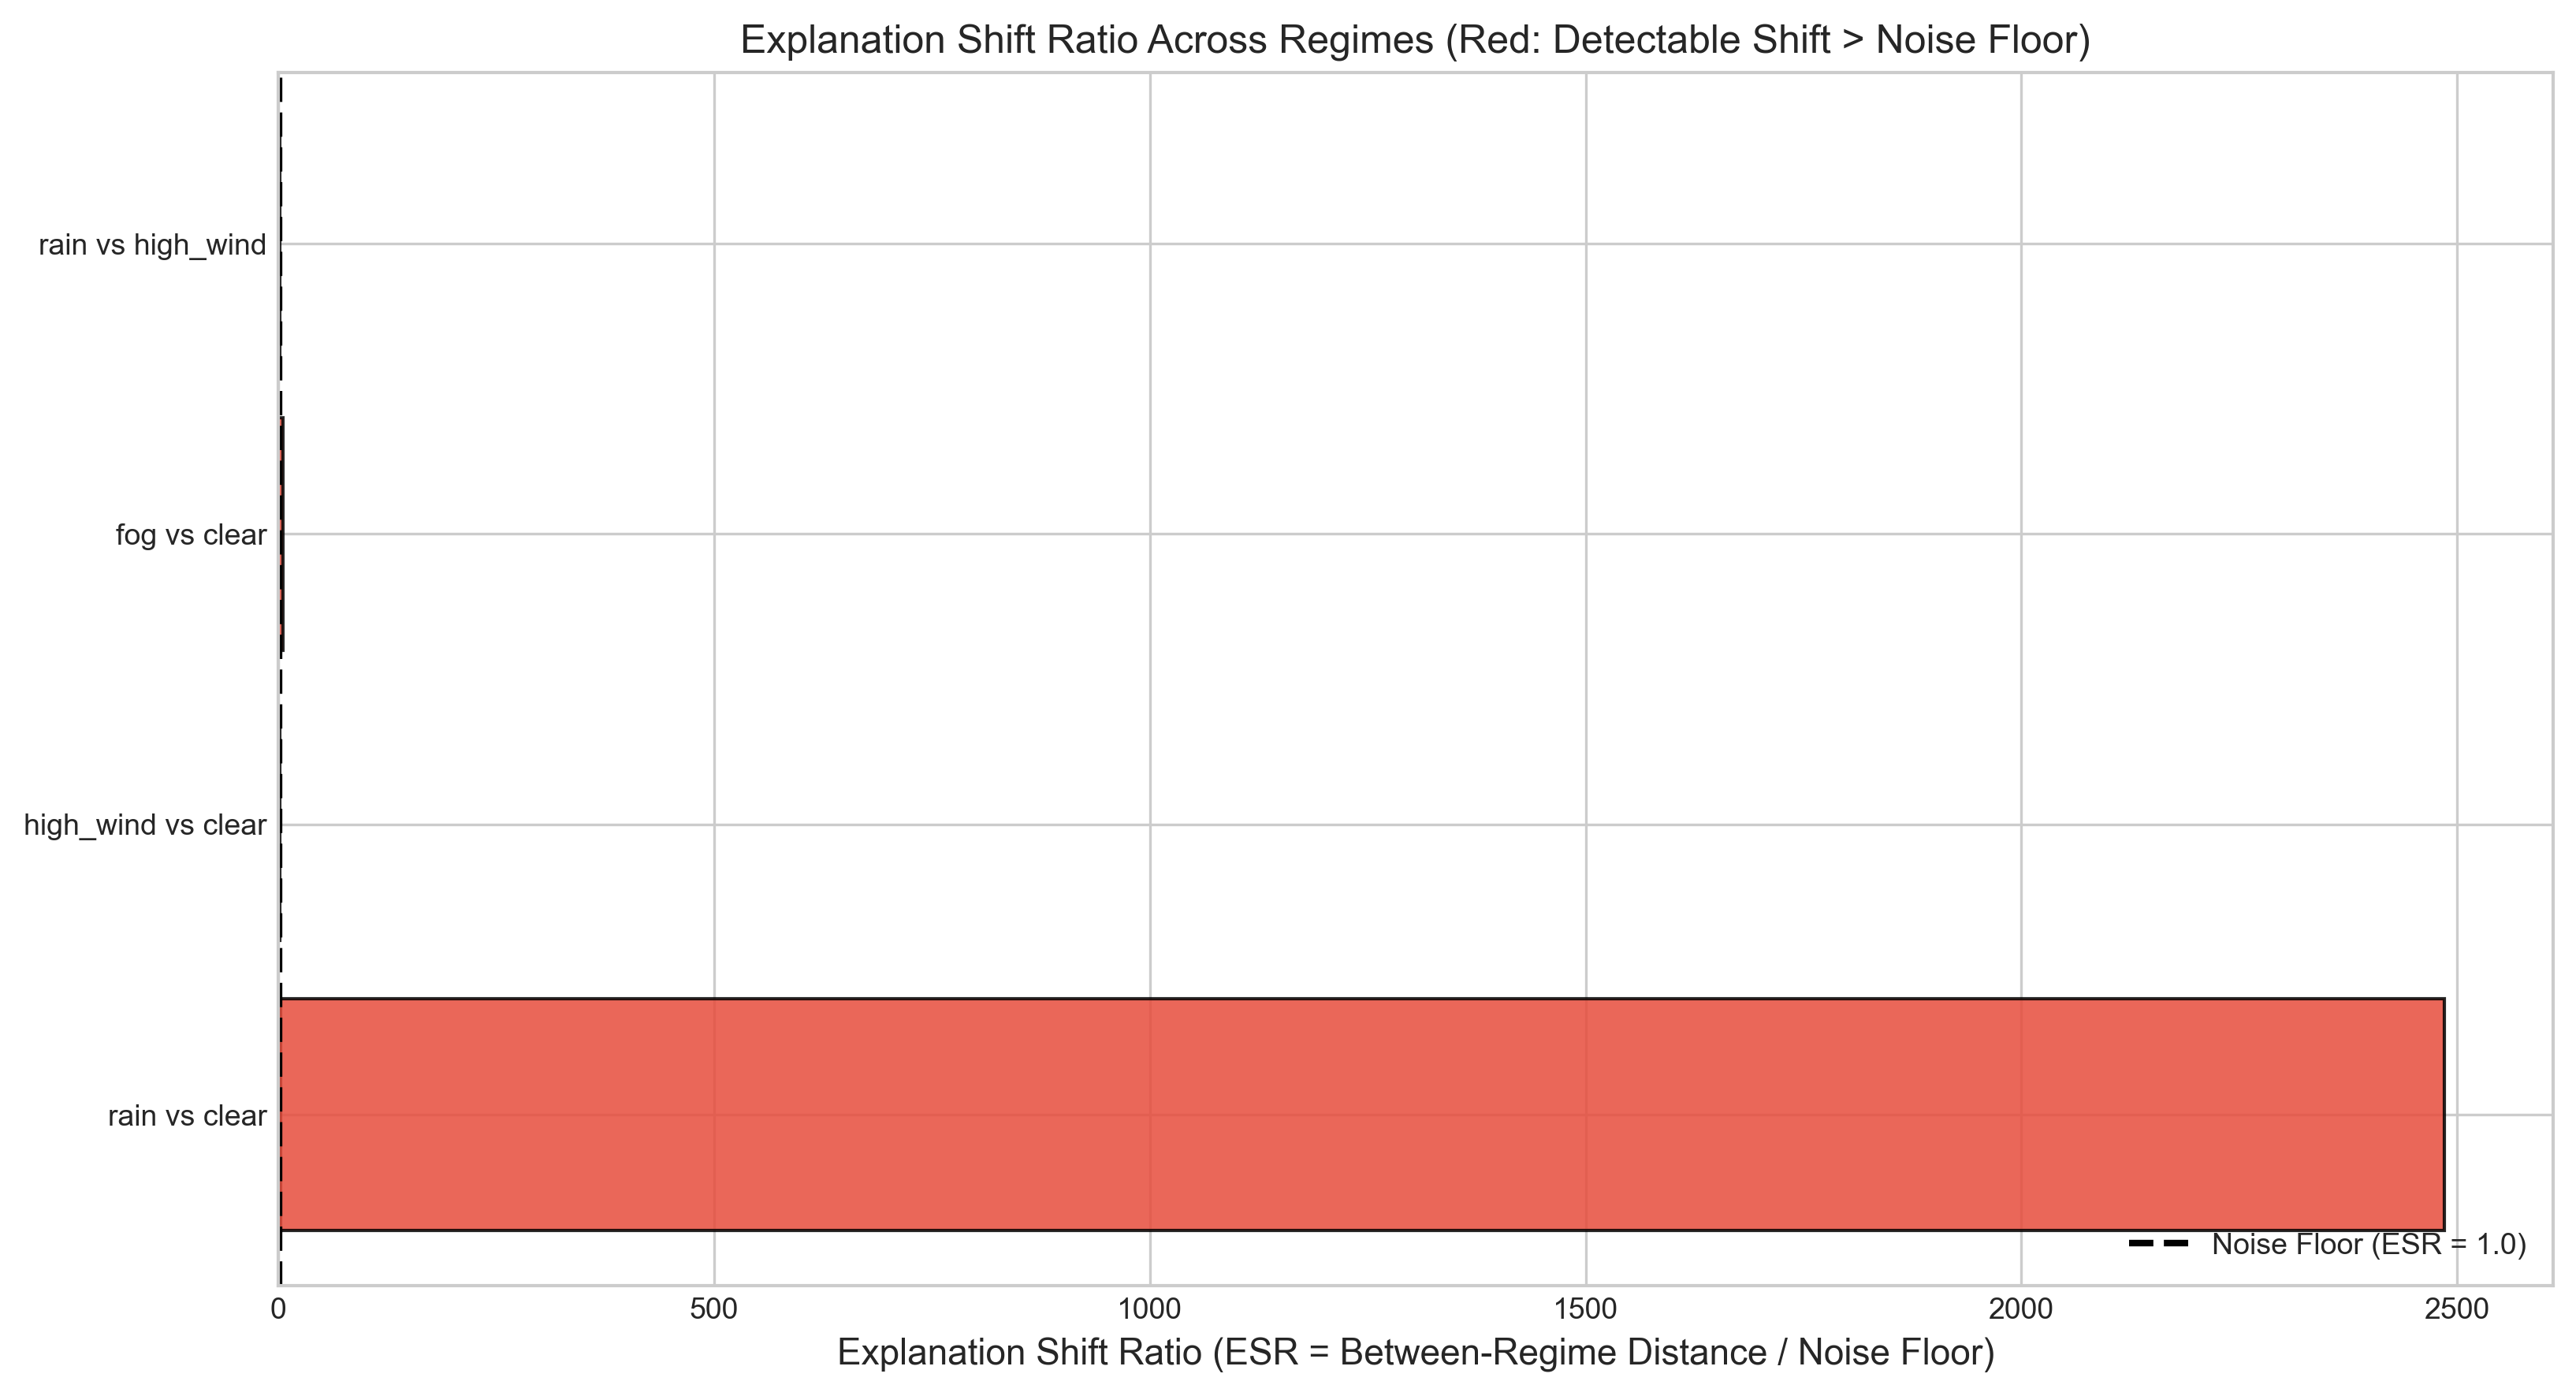

In [2]:
display(Image("figures/fig6_stability_esr_noise_floor.png"))


### Feature Family Shares Across Regimes
We examine whether the relative shares of Weather, Road, Traffic, and Time/Light shift under adverse conditions.


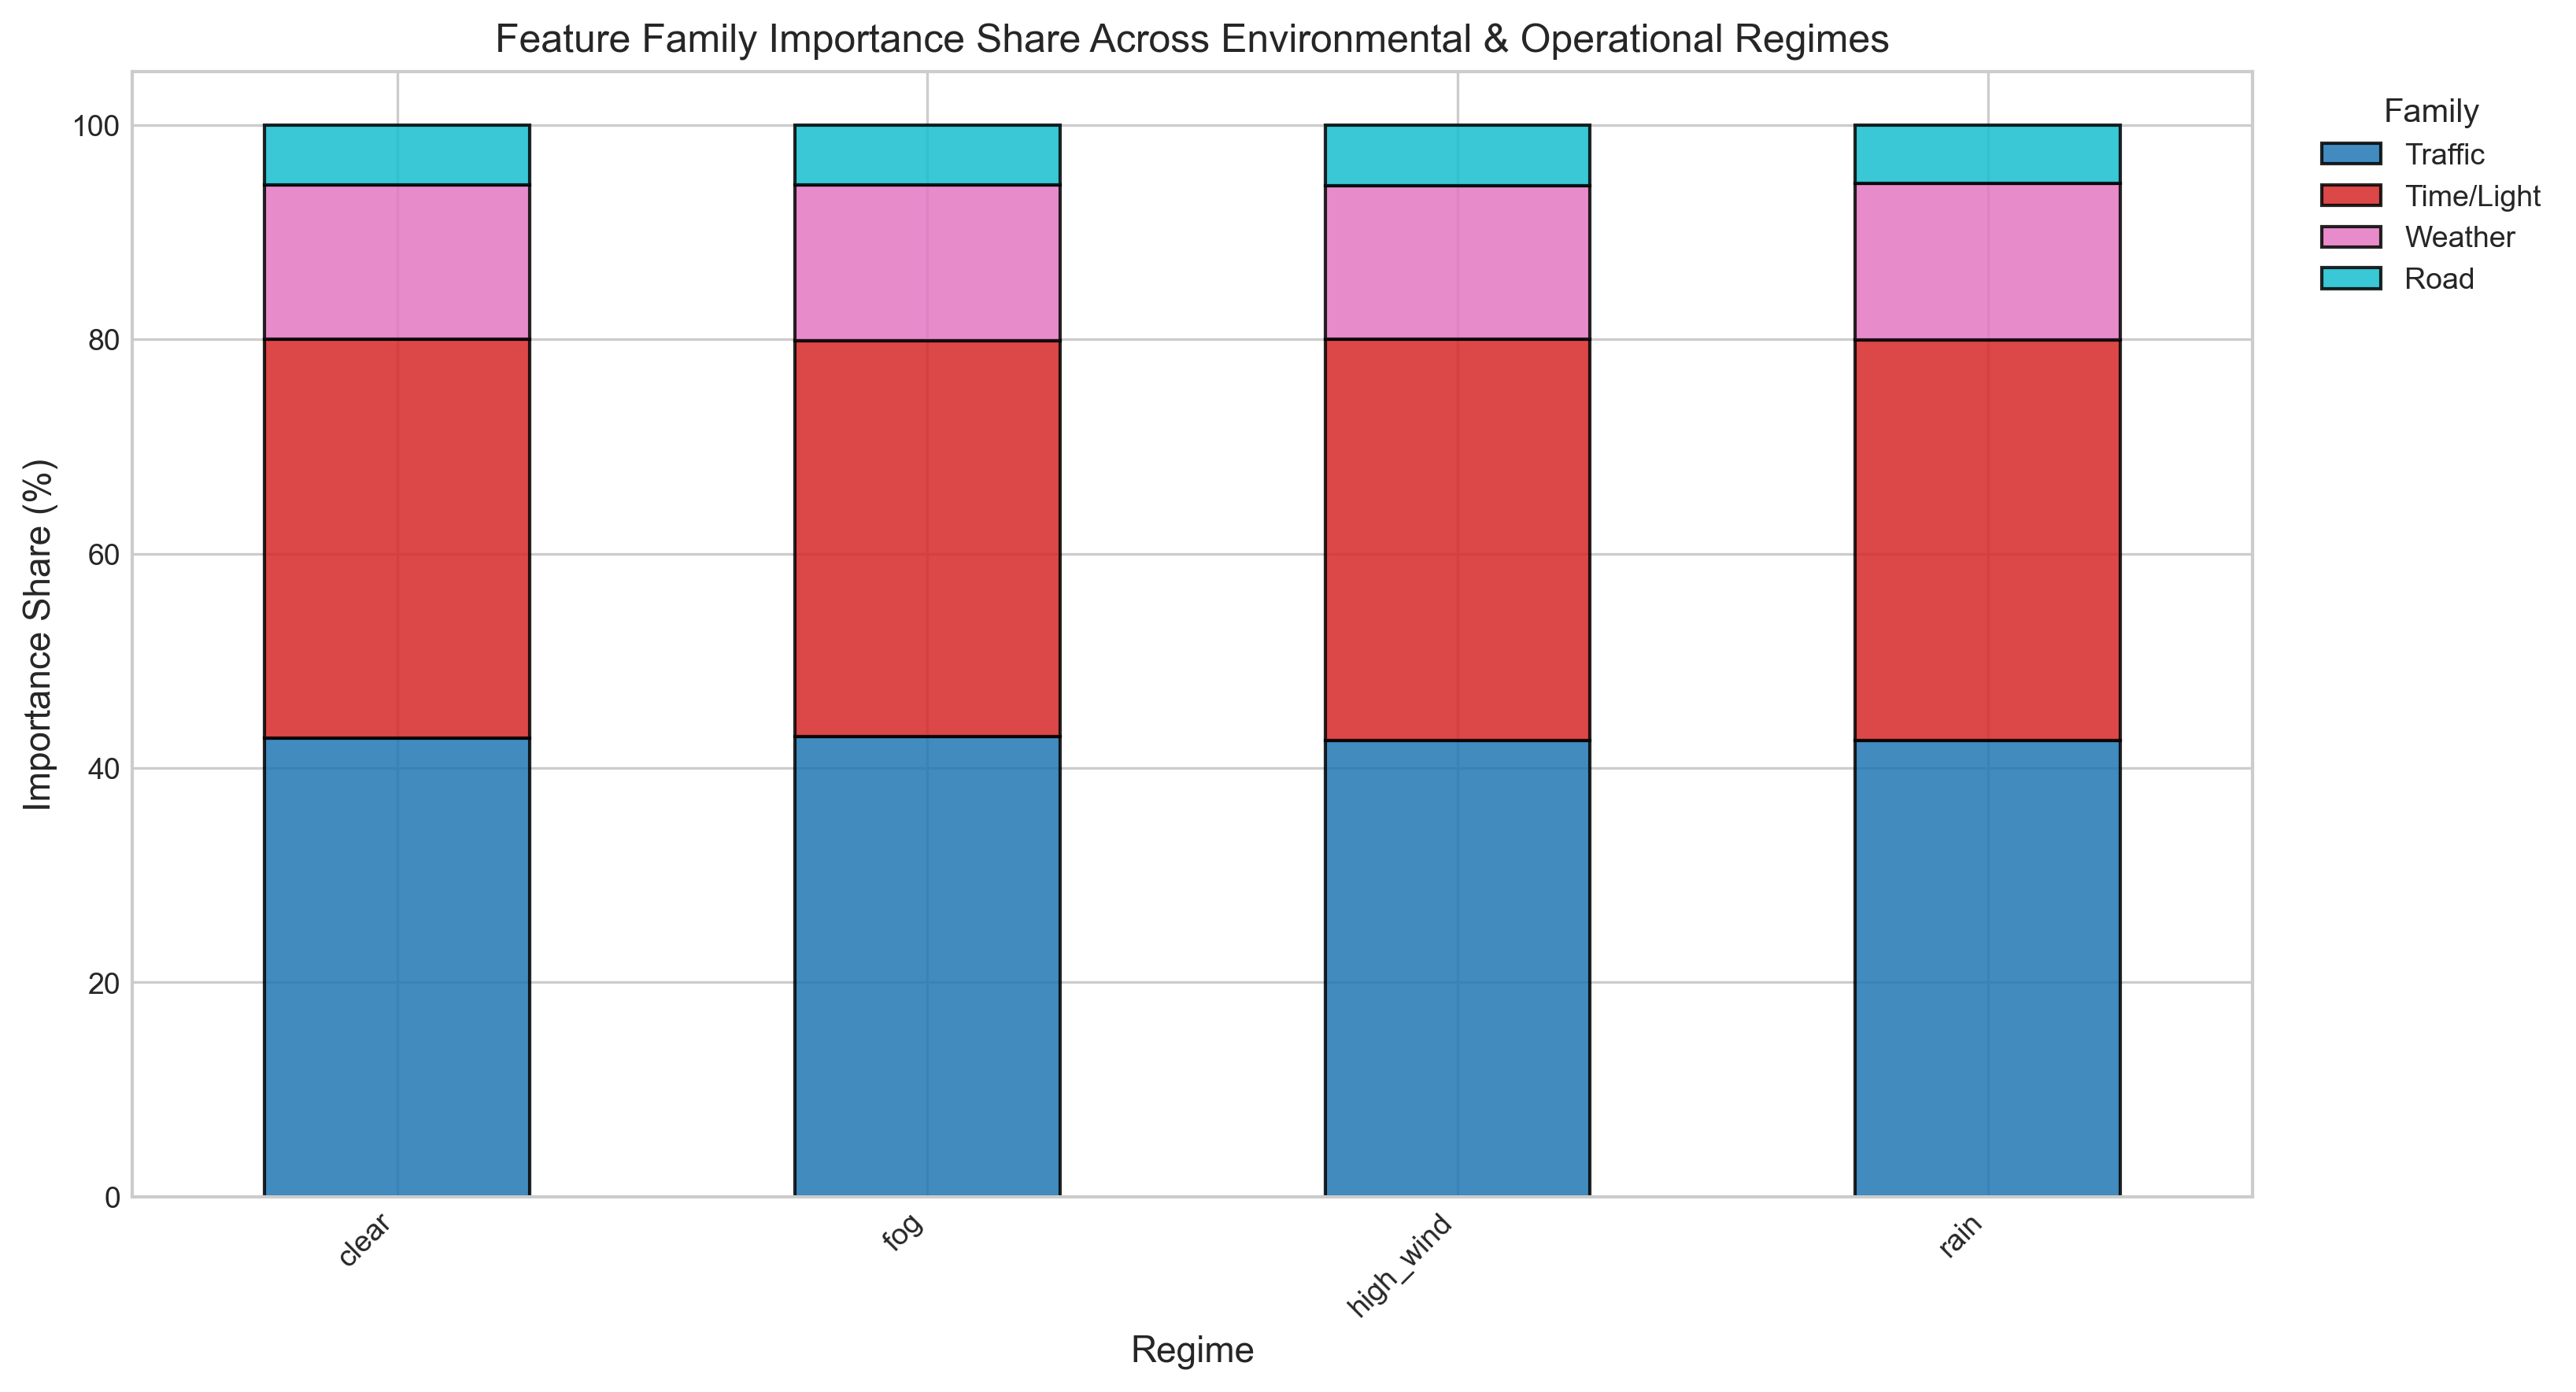

,Weather,Road,Traffic,Time/Light,regime,model,sample_count
0,14.411355,5.603867,42.802066,37.182710,clear,XGBoost,6889
1,14.511951,5.582906,42.952452,36.952693,fog,XGBoost,442
2,14.311659,5.683326,42.561772,37.443242,high_wind,XGBoost,1984
3,14.615517,5.467801,42.545384,37.371295,rain,XGBoost,685


In [3]:
display(Image("figures/fig4_feature_families_regimes.png"))
fam_df = pd.read_csv("results/tables/feature_family_shares.csv")
fam_df


### Stability Findings & Scientific Takeaway
Under Protocol P1 (Global Model Sliced), between-regime shifts are small and do not reach statistical significance after Holm-Bonferroni correction (p_holm = 1.0). However, under Protocol P2 (Per-Regime Models), explanations diverge substantially (ESR = 2485.7, p_holm = 0.001), and this divergence survives propensity-score covariate balancing, confirming that conditional model retraining induces genuine adaptation to distinct operational regimes.
